## Step 1: Explore the dataset

In [2]:
import pandas as pd              # works with tables of data
import numpy as np               # maths
import matplotlib.pyplot as plt  # plotting
import seaborn as sns            # nicer plots

In [3]:
# This Kaggle version of the file uses ',' as the separator (the default)
bank_df = pd.read_csv('../data/bank.csv')
print("Rows, Columns:", bank_df.shape)
bank_df.head()

Rows, Columns: (11162, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


In [4]:
bank_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11162 entries, 0 to 11161
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        11162 non-null  int64 
 1   job        11162 non-null  object
 2   marital    11162 non-null  object
 3   education  11162 non-null  object
 4   default    11162 non-null  object
 5   balance    11162 non-null  int64 
 6   housing    11162 non-null  object
 7   loan       11162 non-null  object
 8   contact    11162 non-null  object
 9   day        11162 non-null  int64 
 10  month      11162 non-null  object
 11  duration   11162 non-null  int64 
 12  campaign   11162 non-null  int64 
 13  pdays      11162 non-null  int64 
 14  previous   11162 non-null  int64 
 15  poutcome   11162 non-null  object
 16  deposit    11162 non-null  object
dtypes: int64(7), object(10)
memory usage: 1.4+ MB


In [5]:
target_col = 'deposit'
numeric_features = bank_df.select_dtypes(include='number').columns.tolist()
categorical_features = [c for c in bank_df.select_dtypes(include='object').columns if c != target_col]

print("Numeric features    :", len(numeric_features), numeric_features)
print("Categorical features:", len(categorical_features), categorical_features)

Numeric features    : 7 ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
Categorical features: 9 ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


In [6]:
print("Real blanks (NaN) in the whole table:", bank_df.isnull().sum().sum())

print("\n'unknown' values per column (these are the hidden missing values):")
unknown_counts = (bank_df[categorical_features] == 'unknown').sum()
print(unknown_counts[unknown_counts > 0])

Real blanks (NaN) in the whole table: 0

'unknown' values per column (these are the hidden missing values):
job            70
education     497
contact      2346
poutcome     8326
dtype: int64


In [7]:
print("Duplicate rows:", bank_df.duplicated().sum())

Duplicate rows: 0


deposit
no     5873
yes    5289
Name: count, dtype: int64

Percentage:
deposit
no     52.62
yes    47.38
Name: proportion, dtype: float64


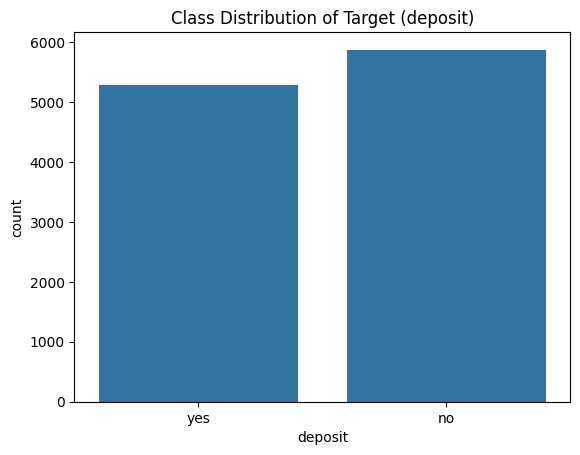

In [8]:
print(bank_df[target_col].value_counts())
print("\nPercentage:")
print((bank_df[target_col].value_counts(normalize=True) * 100).round(2))

sns.countplot(x=target_col, data=bank_df)
plt.title('Class Distribution of Target (deposit)')
plt.show()

## Step 2: Data preprocessing

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# A fixed seed means the "random" split comes out the same every time we run it
RANDOM_SEED = 2026

In [11]:
data = bank_df.copy()   # work on a copy, keep the original untouched

# 1. Duplicates
rows_before = len(data)
data = data.drop_duplicates()
print("Duplicates removed:", rows_before - len(data))

# 2. Drop 'duration' (only known after the call ends, so it leaks the answer)
data = data.drop(columns=['duration'])

# 3. Missing values:
#    job & education have only a few 'unknown' -> mark them as missing (NaN)
#    so they can be filled later with the most common value (learned from TRAIN only).
#    contact & poutcome have many 'unknown' -> keep 'unknown' as its own category.
for col in ['job', 'education']:
    data[col] = data[col].replace('unknown', np.nan)

print("\nMissing values now marked as NaN:")
print(data[['job', 'education']].isnull().sum())

Duplicates removed: 0

Missing values now marked as NaN:
job           70
education    497
dtype: int64


In [12]:
# Target: convert yes/no into 1/0
y = data['deposit'].map({'yes': 1, 'no': 0})
X = data.drop(columns=['deposit'])

num_cols = X.select_dtypes(include='number').columns.tolist()
cat_cols = X.select_dtypes(include='object').columns.tolist()

print("X shape:", X.shape)
print("Numeric columns    :", num_cols)
print("Categorical columns:", cat_cols)

X shape: (11162, 15)
Numeric columns    : ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']
Categorical columns: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,            # 20% for testing
    stratify=y,                # keep the same yes/no ratio in both sets
    random_state=RANDOM_SEED   # same split every run
)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("\nClass % in TRAIN:\n", (y_train.value_counts(normalize=True) * 100).round(2))
print("\nClass % in TEST:\n",  (y_test.value_counts(normalize=True) * 100).round(2))

Train: (8929, 15)  Test: (2233, 15)

Class % in TRAIN:
 deposit
0    52.62
1    47.38
Name: proportion, dtype: float64

Class % in TEST:
 deposit
0    52.62
1    47.38
Name: proportion, dtype: float64


In [14]:
# Numbers -> scale them
numeric_pipeline = Pipeline([
    ('scaler', StandardScaler())
])

# Text -> fill missing with most common value, then one-hot encode
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer([
    ('num', numeric_pipeline, num_cols),
    ('cat', categorical_pipeline, cat_cols)
])

# fit_transform on TRAIN (learns averages, most common values, categories)
X_train_prep = preprocessor.fit_transform(X_train)
# only transform on TEST (uses what was learned from train, so no peeking)
X_test_prep = preprocessor.transform(X_test)

print("Train after preprocessing:", X_train_prep.shape)
print("Test after preprocessing :", X_test_prep.shape)
print("Missing values left in train:", np.isnan(X_train_prep).sum())

Train after preprocessing: (8929, 48)
Test after preprocessing : (2233, 48)
Missing values left in train: 0


In [15]:
# Save the original (raw) rows that ended up in the test set
test_data = bank_df.loc[X_test.index]
test_data.to_csv('../test_data.csv', index=False)
print("Saved test_data.csv with", test_data.shape[0], "rows")

Saved test_data.csv with 2233 rows


## Step 3: Models and Evaluation

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score,
                             recall_score, f1_score, matthews_corrcoef,
                             confusion_matrix)

In [33]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=RANDOM_SEED),
    'Decision Tree': DecisionTreeClassifier(max_depth=6, min_samples_leaf=20,
                                            random_state=RANDOM_SEED),
    'kNN': KNeighborsClassifier(n_neighbors=15),
    'Naive Bayes': GaussianNB(),
    'Random Forest (Ensemble)': RandomForestClassifier(n_estimators=200, max_depth=12,
                                                       random_state=RANDOM_SEED, n_jobs=-1)
}

In [35]:
results = []

for name, model in models.items():
    model.fit(X_train_prep, y_train)                  # learn from TRAIN

    y_pred = model.predict(X_test_prep)               # predicted class (0/1)
    y_prob = model.predict_proba(X_test_prep)[:, 1]   # probability of "yes" (needed for AUC)

    results.append({
        'ML Model Name': name,
        'Accuracy':  accuracy_score(y_test, y_pred),
        'AUC':       roc_auc_score(y_test, y_prob),
        'Precision': precision_score(y_test, y_pred),
        'Recall':    recall_score(y_test, y_pred),
        'F1':        f1_score(y_test, y_pred),
        'MCC':       matthews_corrcoef(y_test, y_pred)
    })

    print(f"{name} - done")
    print("Confusion matrix [[TN FP] [FN TP]]:\n", confusion_matrix(y_test, y_pred), "\n")

Logistic Regression - done
Confusion matrix [[TN FP] [FN TP]]:
 [[953 222]
 [455 603]] 

Decision Tree - done
Confusion matrix [[TN FP] [FN TP]]:
 [[955 220]
 [469 589]] 

kNN - done
Confusion matrix [[TN FP] [FN TP]]:
 [[947 228]
 [435 623]] 

Naive Bayes - done
Confusion matrix [[TN FP] [FN TP]]:
 [[987 188]
 [533 525]] 

Random Forest (Ensemble) - done
Confusion matrix [[TN FP] [FN TP]]:
 [[988 187]
 [408 650]] 



In [37]:
results_df = pd.DataFrame(results).set_index('ML Model Name').round(4)
results_df

,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.6968,0.7554,0.7309,0.5699,0.6405,0.3942
Decision Tree,0.6914,0.7420,0.7281,0.5567,0.6310,0.3838
kNN,0.7031,0.7547,0.7321,0.5888,0.6527,0.4059
Naive Bayes,0.6771,0.7332,0.7363,0.4962,0.5929,0.3601
Random Forest (Ensemble),0.7335,0.7942,0.7766,0.6144,0.6860,0.4695


In [39]:
results_df.to_csv('../model_results.csv')
print("Saved model_results.csv")

Saved model_results.csv


## Step 4: Visualising Model Performance

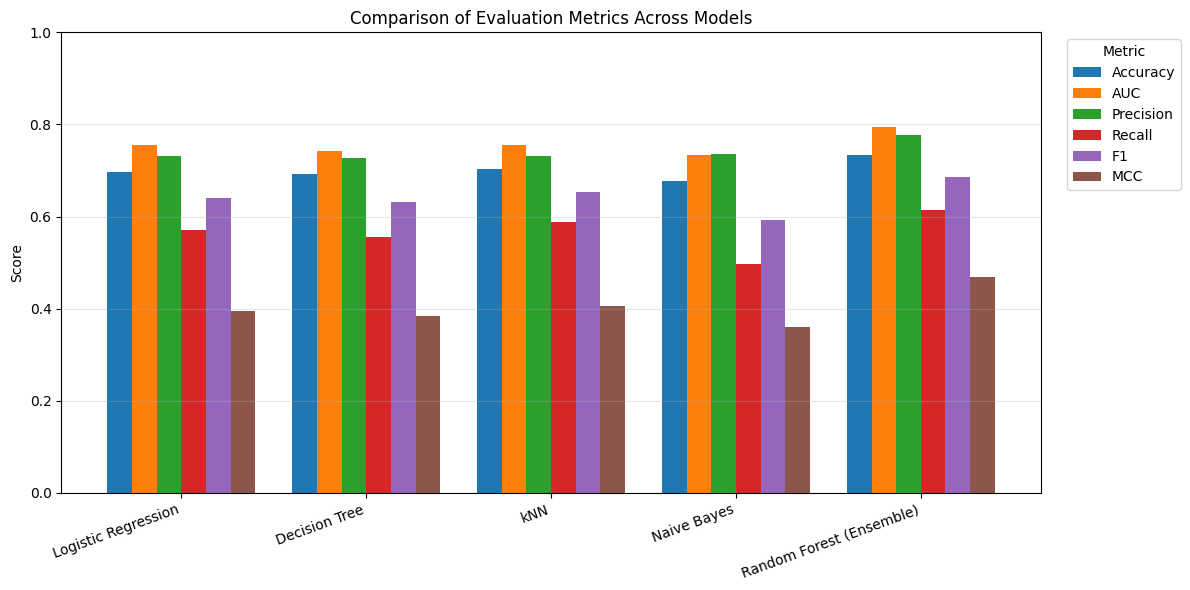

In [42]:
ax = results_df.plot(kind='bar', figsize=(12, 6), width=0.8)
plt.title('Comparison of Evaluation Metrics Across Models')
plt.ylabel('Score')
plt.xlabel('')
plt.ylim(0, 1)
plt.xticks(rotation=20, ha='right')
plt.legend(title='Metric', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('../metrics_comparison.png', dpi=150)   # saved for the README
plt.show()

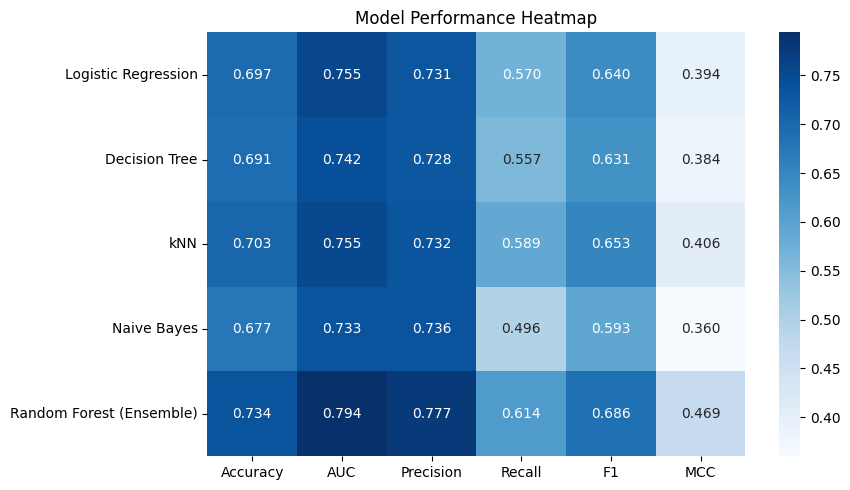

In [44]:
plt.figure(figsize=(9, 5))
sns.heatmap(results_df, annot=True, fmt='.3f', cmap='Blues')
plt.title('Model Performance Heatmap')
plt.ylabel('')
plt.tight_layout()
plt.savefig('../metrics_heatmap.png', dpi=150)
plt.show()

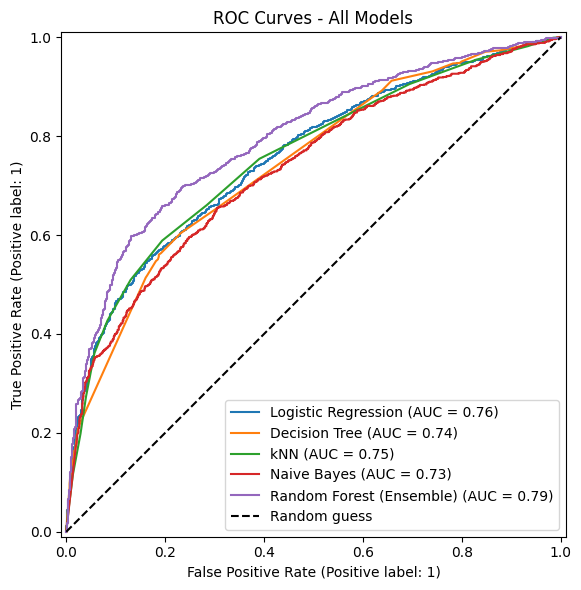

In [46]:
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(8, 6))
for name, model in models.items():
    RocCurveDisplay.from_estimator(model, X_test_prep, y_test, name=name, ax=ax)

ax.plot([0, 1], [0, 1], 'k--', label='Random guess')
ax.set_title('ROC Curves - All Models')
ax.legend()
plt.tight_layout()
plt.savefig('../roc_curves.png', dpi=150)
plt.show()